분류classfication : 지도학습
 학습 이후 데이터에 대한 결과 예측
군집화clustering : 비지도학습
 데이터 그냥 넣어주고 알아서 비슷한거끼리 묶은 결과를 내놔라...

pip install seaborn

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
df = pd.DataFrame()
df["x"] = [80,95,10,90,5]
df["y"] = [20,5,90,10,95]

sns.scatterplot(df,x="x",y="y")
plt.show()

kMeans : 군집화
k=2 >> 데이터를 2그룹으로
랜덤 k점을 생성
기존데이터와 각각 비교
보다 더 가까운쪽으로 그룹화
그룹 내에서 평...균내서 재그룹화 >> 그룹 변화가 생기지 않을때까지 반복



In [ ]:
from sklearn.cluster import KMeans

data = df[["x","y"]].to_numpy()
km = KMeans(2)
print(km.fit_predict(data)) # [0 0 1 0 1]
print(data)
df["group"] = km.fit_predict(data)
sns.scatterplot(df,x="x",y="y",palette="Grays",hue="group")
plt.show()

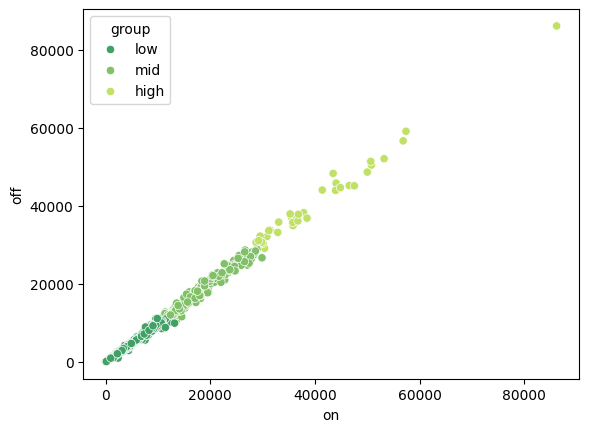

In [ ]:


subDf = pd.read_csv("./subway.csv",names=["y","m","d","line","station","on","off"])
# 2015,01,01,1호선,서울역,47071,40197


onoff_LinePdf = subDf.groupby("station")[["on","off"]].mean()
onoff_LineDf = onoff_LinePdf.to_numpy()

km = KMeans(3)
onoff_LinePdf["group"] = km.fit_predict(onoff_LineDf)
onoff_LinePdf["group"] = onoff_LinePdf["group"].replace([0,1,2],["low","mid","high"])

sns.scatterplot(onoff_LinePdf,x="on",y="off",palette="summer",hue="group")
plt.show()




In [32]:
name = input("station : ")
print(onoff_LinePdf.loc[name]["group"])


high


In [33]:
from sklearn.neighbors import KNeighborsClassifier

featuree = onoff_LinePdf[["on","off"]].to_numpy()
labbel = onoff_LinePdf["group"].to_numpy()

knc = KNeighborsClassifier(10)
knc.fit(featuree,labbel)

on = float(input("on  : "))
off = float(input("off : "))
predData = np.array([[on,off]])

print( knc.predict(predData)[0])


high


naive bayes: 분류
; 자연어처리에 특화
bayes

학습데이터(문장) + label(분류)

BoW(Bag of Words) : 단어 수 세는...
Scikit-learn에 있는 NaiveBayse 사용을 위해 전처리용;


In [ ]:
feature = [
    "ab",
    "a ab",
    "a ba",
    "bb a",
    "aa aa b"
    ]

label = [
    "b",
    "a",
    "a",
    "b",
    "a",
    ]

from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
cvResult = cv.fit_transform(feature)
print(cvResult)     # > (좌표) 값 형태
print(cvResult.toarray()) # 행렬형태
cv.get_feature_names_out() # 전체 단어들

  (np.int32(0), np.int32(1))	1
  (np.int32(1), np.int32(1))	1
  (np.int32(2), np.int32(2))	1
  (np.int32(3), np.int32(3))	1
  (np.int32(4), np.int32(0))	2
[[0 1 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [2 0 0 0]]


array(['aa', 'ab', 'ba', 'bb'], dtype=object)

In [3]:
from sklearn.naive_bayes import MultinomialNB


mnb = MultinomialNB()
mnb.fit(cvResult,label)

MultinomialNB()

In [5]:
s= input("ab:")
sCvResult = cv.transform([s])
print(sCvResult)

result = mnb.predict(sCvResult)
print(result[0])


a
